<div style="background:linear-gradient(90deg,#4F46E5,#7E22CE); color:white; padding:26px 28px; border-radius:10px;">
<div style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.85em; opacity:0.85; letter-spacing:0.08em;">INF672 / UNIDAD 3 / NOTEBOOK DE APOYO</div>
<div style="font-size:0.95em; margin-top:10px; opacity:0.9;">REGRESIÓN Y FLUJO DE TRABAJO DEL MACHINE LEARNING</div>
<div style="font-size:2.1em; font-weight:700; margin-top:4px;">3.4 Métricas de evaluación</div>
<div style="font-size:0.9em; margin-top:14px; opacity:0.9;">M. Sc. Huáscar Fedor Gonzales Guzmán · Carrera de Ingeniería Informática · UATF · Gestión 2026-02</div>
</div>

Este notebook acompaña el **cuaderno de apuntes 3.4**. La idea no es solo *usar* las funciones de `sklearn.metrics`, sino **reconstruir cada métrica a mano con NumPy**, comprobar que coincide con scikit-learn y ver experimentalmente cuándo cada una nos informa bien… y cuándo nos engaña.

**Objetivos de aprendizaje.** Al terminar podrás:

1. Calcular e interpretar MSE, RMSE, MAE, R², R² ajustado y MAPE, y elegir entre ellos según el problema.
2. Construir una matriz de confusión y derivar de ella accuracy, precision, recall, especificidad, F1 y Fβ.
3. Explicar por qué la accuracy engaña con clases desbalanceadas.
4. Mover el umbral de decisión y razonar sobre el costo de cada tipo de error.
5. Interpretar la curva ROC, el AUC y la curva precision–recall.

**Contenido**

| Parte | Tema |
|---|---|
| 0 | Configuración del entorno |
| 3.4.1 | Métricas de regresión: MSE, RMSE, MAE, R², R² ajustado, MAPE |
| 3.4.2 | Métricas de clasificación: matriz de confusión, accuracy, precision, recall, F1, umbral, ROC/AUC, curva PR |

<div style="border-left:5px solid #6B7280; background:#F9FAFB; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#6B7280; letter-spacing:0.06em;">NOTA · Datos y reproducibilidad</span>
<div style="margin-top:6px;">Para regresión usamos el dataset <b>diabetes</b> (442 pacientes, 89 de prueba) con el modelo lineal del tema 3.3. Para clasificación, <b>breast cancer</b> (569 tumores, 212 malignos, 357 benignos). Todas las particiones usan <code>random_state=42</code>, así que las cifras deben coincidir exactamente con las de los apuntes. Requiere scikit-learn ≥ 1.5 (por <code>root_mean_squared_error</code> y <code>TunedThresholdClassifierCV</code>).</div>
</div>

<div style="border-bottom:2px solid #4F46E5; padding-bottom:4px; margin-top:10px;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; color:#4F46E5; font-weight:700;">0</span>
<span style="font-size:1.5em; font-weight:700;"> Configuración del entorno</span>
</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (
    mean_squared_error, root_mean_squared_error, mean_absolute_error,
    r2_score, mean_absolute_percentage_error,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
)

# Paleta "cuaderno científico" del curso
INDIGO, PURPURA, CORAL, TINTA, GRIS = "#4F46E5", "#7E22CE", "#F43F5E", "#111827", "#9CA3AF"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
np.set_printoptions(precision=3, suppress=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.0


<div style="border-bottom:2px solid #4F46E5; padding-bottom:4px; margin-top:10px;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; color:#4F46E5; font-weight:700;">3.4.1</span>
<span style="font-size:1.5em; font-weight:700;"> Métricas de regresión</span>
</div>

En el tema 3.3 usamos el RMSE para comparar modelos sin discutirlo. Pero **elegir la métrica es una decisión de diseño**: define qué significa "funcionar bien".

En regresión cada predicción $\hat{y}_i$ se compara con el valor real $y_i$. La diferencia

$$e_i = y_i - \hat{y}_i$$

es el **residuo**. Todas las métricas de regresión son maneras distintas de **resumir los $n$ residuos en un solo número**.

### a) Error cuadrático medio (MSE)

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2 \qquad (3.4.1)$$

- Es la misma función de costo que minimizamos en el tema 3.1.
- Al elevar al cuadrado, los errores no se cancelan y **los errores grandes pesan mucho más**: un error de 10 aporta 100.
- Defecto: está en **unidades al cuadrado** (si $y$ está en dólares, el MSE está en dólares²). Excelente para *optimizar* (derivable y convexo), pobre para *comunicar*.

Implementamos las métricas nosotros mismos para entender exactamente qué calculan:

In [2]:
def mse(y, y_hat):
    e = np.asarray(y) - np.asarray(y_hat)
    return np.mean(e**2)

def rmse(y, y_hat):
    return np.sqrt(mse(y, y_hat))

def mae(y, y_hat):
    return np.mean(np.abs(np.asarray(y) - np.asarray(y_hat)))

# ¿Cuánto aporta cada error al MSE?
errores = np.array([1, 2, 5, 10])
pd.DataFrame({"error": errores, "error²": errores**2, "|error|": np.abs(errores)})

,error,error²,|error|
0,1,1,1
1,2,4,2
2,5,25,5
3,10,100,10


### b) Raíz del error cuadrático medio (RMSE)

$$\text{RMSE} = \sqrt{\text{MSE}} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2} \qquad (3.4.2)$$

La raíz devuelve el error a las **unidades de $y$**: se lee como el "error típico" del modelo. Como la raíz es creciente, **ordena los modelos igual que el MSE**. Es la métrica más usada para informar resultados.

### c) Error absoluto medio (MAE)

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i| \qquad (3.4.3)$$

También está en unidades de $y$, pero da el mismo peso relativo a todos los errores: es **más robusto frente a valores atípicos**. Siempre se cumple $\text{MAE} \le \text{RMSE}$; cuanto mayor la brecha, más desiguales son los errores.

<div style="border-left:5px solid #059669; background:#ECFDF5; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#059669; letter-spacing:0.06em;">EJEMPLO · RMSE frente a MAE con un valor atípico</span>
<div style="margin-top:6px;">Dos modelos cometen estos errores absolutos sobre cinco casos: <b>A</b> = 2, 2, 2, 2, 2 y <b>B</b> = 1, 1, 1, 1, 6. Según el MAE son igual de buenos; el RMSE castiga a B por su único error grande. Verifícalo en la celda siguiente.</div>
</div>

In [3]:
ceros = np.zeros(5)                     # tomamos y_hat = 0 para que los "errores" sean los valores dados
modelo_A = np.array([2, 2, 2, 2, 2])
modelo_B = np.array([1, 1, 1, 1, 6])

for nombre, e in [("A", modelo_A), ("B", modelo_B)]:
    print(f"Modelo {nombre}:  MAE = {mae(e, ceros):.2f}   RMSE = {rmse(e, ceros):.2f}")

Modelo A:  MAE = 2.00   RMSE = 2.00
Modelo B:  MAE = 2.00   RMSE = 2.83


¿Cuál es preferible? **Depende del costo del error.** Si un error grande es mucho más grave que varios pequeños (una dosis de medicamento, la carga de un puente), el RMSE refleja mejor el riesgo. Si el costo crece linealmente con el error, el MAE es más fiel.

Veamos cómo reacciona cada métrica cuando **un solo** error crece progresivamente:

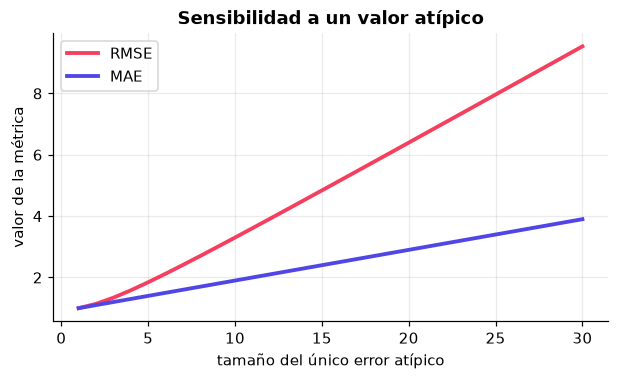

In [4]:
base = np.ones(10)                        # nueve errores de 1 ...
atipicos = np.arange(1, 31)               # ... y un décimo error que crece de 1 a 30
mae_vals, rmse_vals = [], []
for a in atipicos:
    e = base.copy(); e[-1] = a
    mae_vals.append(mae(e, 0)); rmse_vals.append(rmse(e, 0))

plt.figure(figsize=(6.5, 3.4))
plt.plot(atipicos, rmse_vals, color=CORAL, lw=2.5, label="RMSE")
plt.plot(atipicos, mae_vals, color=INDIGO, lw=2.5, label="MAE")
plt.xlabel("tamaño del único error atípico"); plt.ylabel("valor de la métrica")
plt.title("Sensibilidad a un valor atípico"); plt.legend(); plt.show()

### d) Coeficiente de determinación (R²)

El RMSE depende de la escala de $y$: un RMSE de 50 puede ser excelente o pésimo. El **R²** compara el modelo con el predictor más ingenuo posible, el que predice siempre la media $\bar{y}$:

$$R^2 = 1-\frac{SS_{res}}{SS_{tot}}, \qquad SS_{res}=\sum_i (y_i-\hat{y}_i)^2, \qquad SS_{tot}=\sum_i (y_i-\bar{y})^2 \qquad (3.4.4)$$

$SS_{tot}$ es la variabilidad total de $y$; $SS_{res}$, la que el modelo **no** logró explicar. El R² es la **proporción de la varianza de $y$ explicada por el modelo**, sin unidades.

| Valor de R² | Significado |
|---|---|
| $R^2 = 1$ | predicción perfecta |
| $0 < R^2 < 1$ | explica parte de la variabilidad; mejor cuanto más cerca de 1 |
| $R^2 = 0$ | no es mejor que predecir siempre la media |
| $R^2 < 0$ | es **peor** que predecir la media |

In [5]:
def r2(y, y_hat):
    y, y_hat = np.asarray(y), np.asarray(y_hat)
    ss_res = np.sum((y - y_hat)**2)
    ss_tot = np.sum((y - y.mean())**2)
    return 1 - ss_res / ss_tot

y_demo = np.array([2, 4, 5, 4, 5])
print("Predecir la media      →", r2(y_demo, np.full(5, y_demo.mean())))
print("Predicción perfecta    →", r2(y_demo, y_demo))
print("Predecir siempre 10    →", round(r2(y_demo, np.full(5, 10)), 2), "(¡negativo!)")

Predecir la media      → 0.0
Predicción perfecta    → 1.0
Predecir siempre 10    → -30.0 (¡negativo!)


<div style="border-left:5px solid #F43F5E; background:#FFF1F2; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#F43F5E; letter-spacing:0.06em;">ADVERTENCIA · El R² puede ser negativo</span>
<div style="margin-top:6px;">Aunque se llame «R al cuadrado», sobre datos de prueba <b>no</b> es el cuadrado de nada y puede ser negativo sin límite. Solo en el entrenamiento de una regresión lineal con intercepto está garantizado que 0 ≤ R² ≤ 1. Lo comprobamos abajo con el polinomio de grado 3 del tema 3.3, que sobreajustaba.</div>
</div>

Primero recreamos la partición y el modelo del tema 3.3 sobre **diabetes**:

In [6]:
X, y = load_diabetes(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Entrenamiento: {len(y_train)} pacientes   Prueba: {len(y_test)} pacientes")

modelo = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
poli3  = make_pipeline(PolynomialFeatures(3), StandardScaler(), LinearRegression()).fit(X_train, y_train)

for nombre, m in [("Lineal", modelo), ("Polinomio grado 3", poli3)]:
    print(f"{nombre:18s}  R² entrenamiento = {r2_score(y_train, m.predict(X_train)):6.3f}"
          f"   R² prueba = {r2_score(y_test, m.predict(X_test)):7.2f}")

Entrenamiento: 353 pacientes   Prueba: 89 pacientes
Lineal              R² entrenamiento =  0.528   R² prueba =    0.45
Polinomio grado 3   R² entrenamiento =  0.877   R² prueba =  -13.69


El polinomio de grado 3 explica casi todo en entrenamiento, pero en prueba obtiene **R² ≈ −14.56**: sus predicciones son catorce veces peores que usar la media. Es la firma numérica del **sobreajuste**.

### e) R² ajustado

En entrenamiento, el R² **nunca baja** al agregar variables, aunque sean ruido puro. El **R² ajustado** penaliza el número de variables $p$:

$$R^2_{aj} = 1-(1-R^2)\,\frac{n-1}{n-p-1} \qquad (3.4.5)$$

Solo sube si la nueva variable mejora el ajuste más de lo esperable por azar. Comprobémoslo agregando columnas de **ruido aleatorio** al dataset:

In [7]:
def r2_ajustado(r2_val, n, p):
    return 1 - (1 - r2_val) * (n - 1) / (n - p - 1)

rng = np.random.default_rng(42)
filas = []
for k in [0, 10, 50, 100, 200]:                        # columnas de ruido añadidas
    Xr = np.hstack([X_train.values, rng.normal(size=(len(X_train), k))])
    m = LinearRegression().fit(Xr, y_train)
    r2_tr = r2_score(y_train, m.predict(Xr))
    p = Xr.shape[1]
    filas.append({"columnas de ruido": k, "p": p, "R² (train)": r2_tr,
                  "R² ajustado": r2_ajustado(r2_tr, len(y_train), p)})
pd.DataFrame(filas).round(3)

,columnas de ruido,p,R² (train),R² ajustado
0,0,10,0.528,0.514
1,10,20,0.533,0.505
2,50,60,0.628,0.552
3,100,110,0.672,0.523
4,200,210,0.815,0.541


El R² de entrenamiento sube sin parar con ruido; el R² ajustado no se deja engañar. En ML, donde la complejidad se controla con **validación cruzada**, el R² ajustado se usa menos, pero es habitual en informes estadísticos de modelos lineales.

### f) Ejemplo resuelto a mano

Retomemos los cinco puntos del tema 3.1 y la recta ajustada $\hat{y} = 0.6x + 2.2$. Calculamos cada métrica **paso a paso**, como en los apuntes, y luego las contrastamos con scikit-learn.

In [8]:
x = np.array([1, 2, 3, 4, 5])
y_m = np.array([2, 4, 5, 4, 5])
y_hat_m = 0.6 * x + 2.2
e = y_m - y_hat_m

tabla = pd.DataFrame({"x": x, "y": y_m, "ŷ": y_hat_m, "e = y − ŷ": e, "e²": e**2,
                      "|e|": np.abs(e), "(y − ȳ)²": (y_m - y_m.mean())**2})
display(tabla.round(2))

ss_res, ss_tot = np.sum(e**2), np.sum((y_m - y_m.mean())**2)
print(f"SS_res = {ss_res:.2f}   SS_tot = {ss_tot:.2f}")
print(f"MSE  = {ss_res:.2f}/5 = {mse(y_m, y_hat_m):.3f}")
print(f"RMSE = √{mse(y_m, y_hat_m):.2f} = {rmse(y_m, y_hat_m):.3f}")
print(f"MAE  = {np.abs(e).sum():.1f}/5 = {mae(y_m, y_hat_m):.3f}")
print(f"R²   = 1 − {ss_res:.2f}/{ss_tot:.0f} = {r2(y_m, y_hat_m):.3f}")

,x,y,ŷ,e = y − ŷ,e²,|e|,(y − ȳ)²
0,1,2,2.8,-0.8,0.64,0.8,4.0
1,2,4,3.4,0.6,0.36,0.6,0.0
2,3,5,4.0,1.0,1.00,1.0,1.0
3,4,4,4.6,-0.6,0.36,0.6,0.0
4,5,5,5.2,-0.2,0.04,0.2,1.0


SS_res = 2.40   SS_tot = 6.00
MSE  = 2.40/5 = 0.480
RMSE = √0.48 = 0.693
MAE  = 3.2/5 = 0.640
R²   = 1 − 2.40/6 = 0.600


In [9]:
# Contraste con scikit-learn
comparacion = pd.DataFrame({
    "a mano":       [mse(y_m, y_hat_m), rmse(y_m, y_hat_m), mae(y_m, y_hat_m), r2(y_m, y_hat_m)],
    "scikit-learn": [mean_squared_error(y_m, y_hat_m), root_mean_squared_error(y_m, y_hat_m),
                     mean_absolute_error(y_m, y_hat_m), r2_score(y_m, y_hat_m)],
}, index=["MSE", "RMSE", "MAE", "R²"])
comparacion.round(4)

,a mano,scikit-learn
MSE,0.4800,0.4800
RMSE,0.6928,0.6928
MAE,0.6400,0.6400
R²,0.6000,0.6000


### g) Verificación en Python con el dataset diabetes

In [10]:
pred = modelo.predict(X_test)
print(f"MSE  = {mean_squared_error(y_test, pred):.2f}")
print(f"RMSE = {root_mean_squared_error(y_test, pred):.2f}")
print(f"MAE  = {mean_absolute_error(y_test, pred):.2f}")
print(f"R²   = {r2_score(y_test, pred):.3f}")
print(f"MAPE = {mean_absolute_percentage_error(y_test, pred):.1%}")

MSE  = 2900.19
RMSE = 53.85
MAE  = 42.79
R²   = 0.453
MAPE = 37.5%


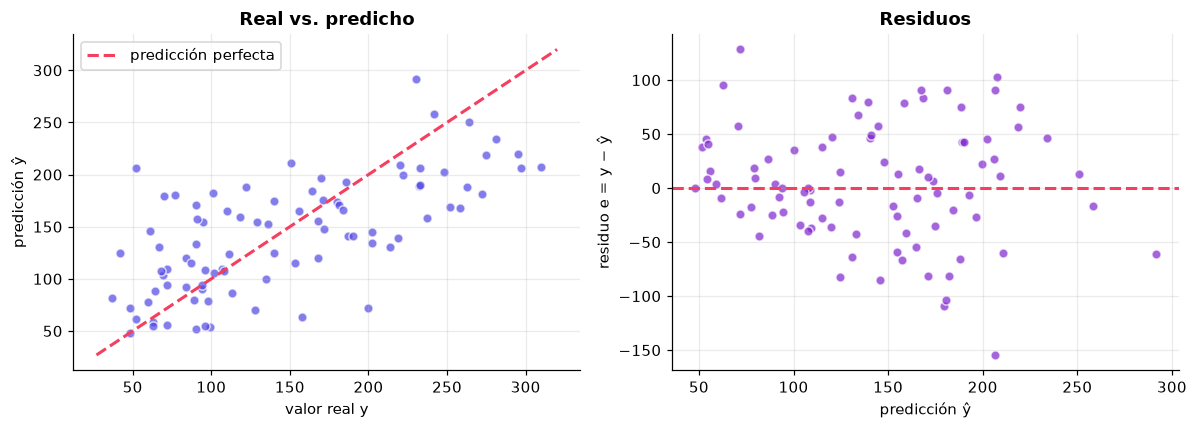

In [11]:
residuos = y_test - pred
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(y_test, pred, color=INDIGO, alpha=0.7, edgecolor="white")
lim = [min(y_test.min(), pred.min()) - 10, max(y_test.max(), pred.max()) + 10]
ax[0].plot(lim, lim, "--", color=CORAL, lw=2, label="predicción perfecta")
ax[0].set(xlabel="valor real y", ylabel="predicción ŷ", title="Real vs. predicho"); ax[0].legend()

ax[1].scatter(pred, residuos, color=PURPURA, alpha=0.7, edgecolor="white")
ax[1].axhline(0, color=CORAL, lw=2, ls="--")
ax[1].set(xlabel="predicción ŷ", ylabel="residuo e = y − ŷ", title="Residuos")
plt.tight_layout(); plt.show()

*Figura 1.* Izquierda: cuanto más cerca de la diagonal, mejor la predicción. Derecha: los residuos se reparten alrededor de cero, con algunos errores superiores a 100.

In [12]:
abs_err = np.abs(residuos)
n, p = X_test.shape
print(f"Error máximo         = {abs_err.max():.1f}")
print(f"Mediana del |error|  = {abs_err.median():.1f}")
print(f"R² ajustado (n={n}, p={p}) = {r2_ajustado(r2_score(y_test, pred), n, p):.3f}")

Error máximo         = 154.5
Mediana del |error|  = 38.0
R² ajustado (n=89, p=10) = 0.382


**Lectura de los resultados.** El error típico es de unas **54 unidades** (RMSE) y el promedio, de **43** (MAE). La brecha entre ambos delata algunos errores grandes: el mayor llega a 154.5, mientras que la mitad de los pacientes tiene un error menor de 38. El modelo explica el **45 %** de la varianza; el R² ajustado baja a **0.382**.

<div style="border-left:5px solid #6B7280; background:#F9FAFB; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#6B7280; letter-spacing:0.06em;">NOTA · MAPE: el error en porcentaje</span>
<div style="margin-top:6px;">MAPE = (1/n) Σ |yᵢ − ŷᵢ| / |yᵢ| expresa el error como porcentaje del valor real: fácil de comunicar («nos equivocamos un 37.5 % en promedio»). Pero <b>se dispara cuando algún yᵢ está cerca de cero</b> y penaliza más las sobreestimaciones que las subestimaciones. Úsalo solo si y es siempre claramente positiva.</div>
</div>

In [13]:
# El problema del MAPE con valores cercanos a cero
y_real = np.array([100, 50, 0.1])
y_pred = np.array([110, 45, 1.0])     # errores absolutos: 10, 5 y apenas 0.9
print(f"MAE  = {mean_absolute_error(y_real, y_pred):.2f}   (razonable)")
print(f"MAPE = {mean_absolute_percentage_error(y_real, y_pred):.0%}  (¡dominado por el caso y = 0.1!)")

MAE  = 5.30   (razonable)
MAPE = 307%  (¡dominado por el caso y = 0.1!)


### h) ¿Qué métrica de regresión usar?

| Métrica | Unidades | Sensible a atípicos | Uso típico |
|---|---|---|---|
| MSE | de $y^2$ | muy alta | función de costo para entrenar |
| RMSE | de $y$ | alta | informar el error; comparar modelos |
| MAE | de $y$ | baja | datos con atípicos; costo lineal del error |
| R² | sin unidades | alta | proporción explicada; comparar entre problemas |
| MAPE | % | media | comunicar a no especialistas (con $y > 0$) |

<div style="border-left:5px solid #4F46E5; background:#EEF2FF; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#4F46E5; letter-spacing:0.06em;">EN MACHINE LEARNING · Informar siempre más de una métrica… y un modelo de referencia</span>
<div style="margin-top:6px;">Ninguna métrica cuenta la historia completa. Informa <b>RMSE y MAE</b> (magnitud del error) junto con <b>R²</b> (calidad relativa) y compáralos con un <b>modelo de referencia</b>. Sin esa referencia, «RMSE = 53.85» no dice si el modelo es bueno o malo. En scikit-learn, <code>DummyRegressor</code> construye esa referencia.</div>
</div>

In [14]:
referencia = DummyRegressor(strategy="mean").fit(X_train, y_train)   # predice siempre la media de train
pred_ref = referencia.predict(X_test)

resumen = pd.DataFrame({
    "Referencia (media)": [root_mean_squared_error(y_test, pred_ref), mean_absolute_error(y_test, pred_ref), r2_score(y_test, pred_ref)],
    "Regresión lineal":   [root_mean_squared_error(y_test, pred),     mean_absolute_error(y_test, pred),     r2_score(y_test, pred)],
}, index=["RMSE", "MAE", "R²"])
resumen.round(3)

,Referencia (media),Regresión lineal
RMSE,73.222,53.853
MAE,64.006,42.794
R²,-0.012,0.453


Observa que el R² de la referencia en prueba no es exactamente 0: usa la media de **entrenamiento**, no la de prueba.

<div style="border-bottom:2px solid #4F46E5; padding-bottom:4px; margin-top:10px;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; color:#4F46E5; font-weight:700;">3.4.2</span>
<span style="font-size:1.5em; font-weight:700;"> Métricas de clasificación</span>
</div>

En clasificación cada predicción es simplemente **correcta o incorrecta**. Pero no todos los errores cuestan lo mismo: diagnosticar como benigno un tumor maligno es mucho más grave que el error contrario. Las métricas de clasificación existen para **distinguir esos tipos de error**.

Preparamos el dataset **breast cancer**. Por convención, la clase **positiva** es la que queremos detectar (aunque sea "mala"): el tumor **maligno**.

In [15]:
datos = load_breast_cancer(as_frame=True)
Xc, yc = datos.data, 1 - datos.target          # el original codifica maligno = 0; lo invertimos → 1 = maligno

print(f"{Xc.shape[0]} tumores, {Xc.shape[1]} medidas por tumor")
print(yc.map({0: "benigno", 1: "maligno"}).value_counts())

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc)
print(f"\nProporción de malignos → train: {yc_tr.mean():.3f}   test: {yc_te.mean():.3f}  (stratify la conserva)")

569 tumores, 30 medidas por tumor
target
benigno    357
maligno    212
Name: count, dtype: int64

Proporción de malignos → train: 0.374   test: 0.368  (stratify la conserva)


Entrenamos una **regresión logística** (la estudiaremos más adelante; por ahora basta saber que estima la probabilidad de que un tumor sea maligno):

In [16]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
clf.fit(Xc_tr, yc_tr)
pred_c = clf.predict(Xc_te)

### a) La matriz de confusión

Al cruzar la clase real con la predicha surgen cuatro casos:

| | **Predicho negativo (0)** | **Predicho positivo (1)** |
|---|---|---|
| **Real negativo (0)** | **VN** · verdadero negativo | **FP** · falso positivo (error tipo I) |
| **Real positivo (1)** | **FN** · falso negativo (error tipo II) | **VP** · verdadero positivo |

Primero la construimos **contando a mano** con máscaras booleanas:

In [17]:
y_r, y_p = yc_te.values, pred_c

VP = np.sum((y_r == 1) & (y_p == 1))
VN = np.sum((y_r == 0) & (y_p == 0))
FP = np.sum((y_r == 0) & (y_p == 1))
FN = np.sum((y_r == 1) & (y_p == 0))
print(f"VN = {VN}   FP = {FP}\nFN = {FN}    VP = {VP}")
print("\nscikit-learn:\n", confusion_matrix(yc_te, pred_c))

VN = 71   FP = 1
FN = 3    VP = 39

scikit-learn:
 [[71  1]
 [ 3 39]]


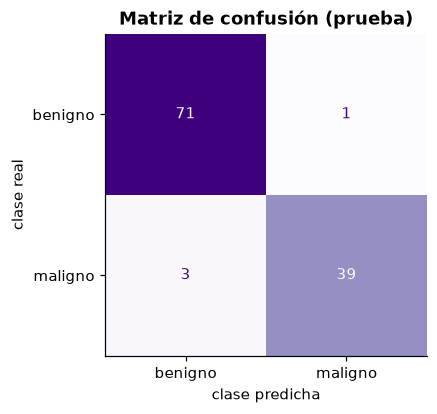

In [18]:
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ConfusionMatrixDisplay.from_predictions(yc_te, pred_c, display_labels=["benigno", "maligno"],
                                        cmap="Purples", colorbar=False, ax=ax)
ax.set(xlabel="clase predicha", ylabel="clase real", title="Matriz de confusión (prueba)")
ax.grid(False); plt.show()

*Figura 2.* De 114 tumores el modelo acierta 110. Se equivoca en un benigno marcado como maligno (**FP = 1**) y en tres malignos marcados como benignos (**FN = 3**): esos falsos negativos son los errores más graves del problema.

<div style="border-left:5px solid #F43F5E; background:#FFF1F2; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#F43F5E; letter-spacing:0.06em;">ADVERTENCIA · El orden de la matriz en scikit-learn</span>
<div style="margin-top:6px;"><code>confusion_matrix</code> pone la <b>clase real en las filas</b> y la <b>predicha en las columnas</b>, de menor a mayor etiqueta: <code>[[VN, FP], [FN, VP]]</code>. Otros libros usan el orden inverso. Un truco útil: <code>vn, fp, fn, vp = confusion_matrix(y, pred).ravel()</code>.</div>
</div>

### b) Exactitud (accuracy)

$$\text{Accuracy} = \frac{VP+VN}{VP+VN+FP+FN} \qquad (3.4.6)$$

Es la proporción de aciertos. Funciona bien con **clases balanceadas** y errores de costo similar; fuera de eso puede engañar gravemente.

In [19]:
acc = (VP + VN) / (VP + VN + FP + FN)
print(f"Accuracy a mano = {acc:.3f}   sklearn = {accuracy_score(yc_te, pred_c):.3f}")

base_c = DummyClassifier(strategy="most_frequent").fit(Xc_tr, yc_tr)   # siempre "benigno"
print(f"Referencia 'siempre benigno' = {accuracy_score(yc_te, base_c.predict(Xc_te)):.3f}")

Accuracy a mano = 0.965   sklearn = 0.965
Referencia 'siempre benigno' = 0.632


<div style="border-left:5px solid #059669; background:#ECFDF5; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#059669; letter-spacing:0.06em;">EJEMPLO · La paradoja de la exactitud</span>
<div style="margin-top:6px;">Un banco revisa 10 000 transacciones, de las cuales <b>100 son fraudes</b> (1 %). Un «modelo» que responde siempre <i>no es fraude</i> obtiene 99 % de exactitud… sin detectar <b>un solo fraude</b>. Simulémoslo.</div>
</div>

In [20]:
y_fraude = np.zeros(10_000, dtype=int); y_fraude[:100] = 1      # 100 fraudes
modelo_perezoso = np.zeros(10_000, dtype=int)                    # siempre "no fraude"

print(f"Accuracy = {accuracy_score(y_fraude, modelo_perezoso):.3f}")
print(f"Recall   = {recall_score(y_fraude, modelo_perezoso):.3f}   ← fraudes detectados: {modelo_perezoso[y_fraude == 1].sum()}")

Accuracy = 0.990
Recall   = 0.000   ← fraudes detectados: 0


### c) Precision, recall y especificidad

$$\text{Precision} = \frac{VP}{VP+FP} \qquad \text{Recall} = \frac{VP}{VP+FN} \qquad (3.4.7)$$

- **Precision** → *de lo que el modelo marcó como positivo, ¿cuánto lo era?* Alta = pocas falsas alarmas.
- **Recall** (sensibilidad) → *de todos los positivos que existen, ¿cuántos encontró?* Alto = se escapan pocos casos.
- **Especificidad** $= VN/(VN+FP)$ → proporción de negativos bien identificados. Sensibilidad y especificidad son el par clásico de los estudios clínicos.

| Situación | Error más costoso | Métrica a priorizar |
|---|---|---|
| Detección de cáncer | no detectar un tumor (FN) | recall |
| Filtro de spam | enviar a spam un correo legítimo (FP) | precision |
| Detección de fraude | dejar pasar un fraude (FN) | recall, con precision aceptable |
| Recomendar productos | mostrar algo irrelevante (FP) | precision |
| Control de calidad industrial | dejar pasar una pieza defectuosa (FN) | recall |

In [21]:
precision = VP / (VP + FP)
recall = VP / (VP + FN)
especificidad = VN / (VN + FP)

print(f"Precision     = {VP}/({VP}+{FP}) = {precision:.3f}   sklearn: {precision_score(yc_te, pred_c):.3f}")
print(f"Recall        = {VP}/({VP}+{FN}) = {recall:.3f}   sklearn: {recall_score(yc_te, pred_c):.3f}")
print(f"Especificidad = {VN}/({VN}+{FP}) = {especificidad:.3f}   sklearn: {recall_score(yc_te, pred_c, pos_label=0):.3f}")

Precision     = 39/(39+1) = 0.975   sklearn: 0.975
Recall        = 39/(39+3) = 0.929   sklearn: 0.929
Especificidad = 71/(71+1) = 0.986   sklearn: 0.986


Nota el truco de la última línea: la **especificidad es el recall de la clase negativa** (`pos_label=0`).

Hay una **tensión** entre precision y recall. Dos casos extremos lo muestran:

In [22]:
todo_positivo = np.ones_like(y_r)                       # marca todo como maligno
solo_seguro = np.zeros_like(y_r)
proba_tmp = clf.predict_proba(Xc_te)[:, 1]
solo_seguro[np.argmax(proba_tmp)] = 1                   # marca solo el caso más seguro

for nombre, p_ in [("Todo positivo", todo_positivo), ("Solo el más seguro", solo_seguro)]:
    print(f"{nombre:20s} precision = {precision_score(y_r, p_):.3f}   recall = {recall_score(y_r, p_):.3f}")

Todo positivo        precision = 0.368   recall = 1.000
Solo el más seguro   precision = 1.000   recall = 0.024


### d) F1-score

Resume precision y recall con su **media armónica**:

$$F_1 = 2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}} \qquad (3.4.8)$$

La media armónica es dura con los desequilibrios: un F1 alto exige que **ambas** métricas sean altas.

Media aritmética = 0.55
F1 (armónica)    = 0.18


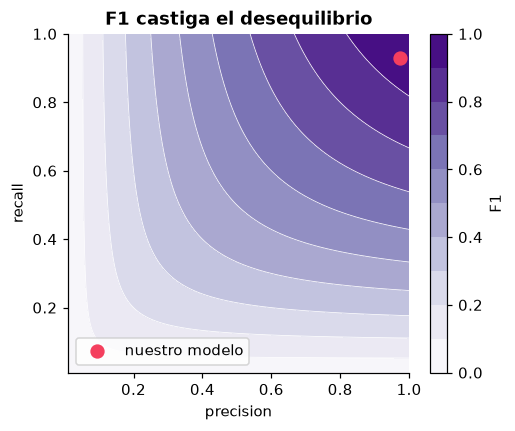

In [23]:
P_, R_ = 1.0, 0.1
print(f"Media aritmética = {(P_ + R_) / 2:.2f}")
print(f"F1 (armónica)    = {2 * P_ * R_ / (P_ + R_):.2f}")

# Mapa: F1 para todas las combinaciones de precision y recall
pp, rr = np.meshgrid(np.linspace(0.01, 1, 200), np.linspace(0.01, 1, 200))
f1_grid = 2 * pp * rr / (pp + rr)
plt.figure(figsize=(5, 4))
cs = plt.contourf(pp, rr, f1_grid, levels=10, cmap="Purples")
plt.contour(pp, rr, f1_grid, levels=10, colors="white", linewidths=0.5)
plt.colorbar(cs, label="F1"); plt.scatter([precision], [recall], color=CORAL, s=70, zorder=3, label="nuestro modelo")
plt.xlabel("precision"); plt.ylabel("recall"); plt.title("F1 castiga el desequilibrio"); plt.legend(loc="lower left")
plt.grid(False); plt.show()

<div style="border-left:5px solid #6B7280; background:#F9FAFB; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#6B7280; letter-spacing:0.06em;">NOTA · El F-beta: cuando un error importa más</span>
<div style="margin-top:6px;">Fβ = (1 + β²)·P·R / (β²·P + R). Con <b>β = 2</b> el recall pesa más (diagnóstico médico); con <b>β = 0.5</b> pesa más la precision (filtros de spam). En scikit-learn: <code>fbeta_score(y, pred, beta=2)</code>.</div>
</div>

In [24]:
for beta in [0.5, 1, 2]:
    print(f"F{beta:<3} = {fbeta_score(yc_te, pred_c, beta=beta):.3f}")

F0.5 = 0.965
F1   = 0.951
F2   = 0.938


Como nuestro modelo tiene precision (0.975) > recall (0.929), el F2 —que premia el recall— es el más bajo.

### e) Ejemplo resuelto a mano

Con VN = 71, FP = 1, FN = 3 y VP = 39 (Figura 2), reunimos todo en una función reutilizable:

In [25]:
def metricas_desde_matriz(vn, fp, fn, vp):
    P = vp / (vp + fp); R = vp / (vp + fn)
    return pd.Series({
        "Accuracy": (vp + vn) / (vp + vn + fp + fn),
        "Precision": P, "Recall": R,
        "Especificidad": vn / (vn + fp),
        "F1": 2 * P * R / (P + R),
    })

metricas_desde_matriz(71, 1, 3, 39).round(3)

Accuracy         0.965
Precision        0.975
Recall           0.929
Especificidad    0.986
F1               0.951
dtype: float64

### f) Verificación en Python: `classification_report`

In [26]:
print(classification_report(yc_te, pred_c, digits=3, target_names=["benigno", "maligno"]))

              precision    recall  f1-score   support

     benigno      0.959     0.986     0.973        72
     maligno      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114



`classification_report` calcula precision, recall y F1 **para cada clase**, tratándola en turno como positiva. La fila *maligno* reproduce nuestros cálculos; en la fila *benigno*, el recall 0.986 **es la especificidad**. La columna `support` cuenta los casos reales de cada clase.

<div style="border-left:5px solid #4F46E5; background:#EEF2FF; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#4F46E5; letter-spacing:0.06em;">EN MACHINE LEARNING · Promedios en problemas multiclase</span>
<div style="margin-top:6px;">Con más de dos clases las métricas se calculan por clase y se promedian. El <b>promedio macro</b> da el mismo peso a cada clase (una clase pequeña con mal desempeño se nota); el <b>ponderado</b> pondera por el <code>support</code> y refleja sobre todo a las clases grandes. Con clases desbalanceadas, el macro es el más honesto.</div>
</div>

In [27]:
# Ejemplo sintético: tres clases muy desbalanceadas; la clase rara "C" se predice fatal
y_mc  = np.array(["A"] * 80 + ["B"] * 15 + ["C"] * 5)
p_mc  = np.array(["A"] * 80 + ["B"] * 14 + ["A"] + ["A"] * 4 + ["C"])
print(classification_report(y_mc, p_mc, digits=3, zero_division=0))
print(f"F1 macro    = {f1_score(y_mc, p_mc, average='macro'):.3f}")
print(f"F1 weighted = {f1_score(y_mc, p_mc, average='weighted'):.3f}   ← oculta el fracaso en C")

              precision    recall  f1-score   support

           A      0.941     1.000     0.970        80
           B      1.000     0.933     0.966        15
           C      1.000     0.200     0.333         5

    accuracy                          0.950       100
   macro avg      0.980     0.711     0.756       100
weighted avg      0.953     0.950     0.937       100

F1 macro    = 0.756
F1 weighted = 0.937   ← oculta el fracaso en C


### g) El umbral de decisión

La regresión logística produce una **probabilidad** $p = P(\text{maligno}\mid x)$. El método `predict` aplica un **umbral de 0.5**, pero eso es solo una convención. Con `predict_proba` podemos elegir otro umbral según el costo de cada error.

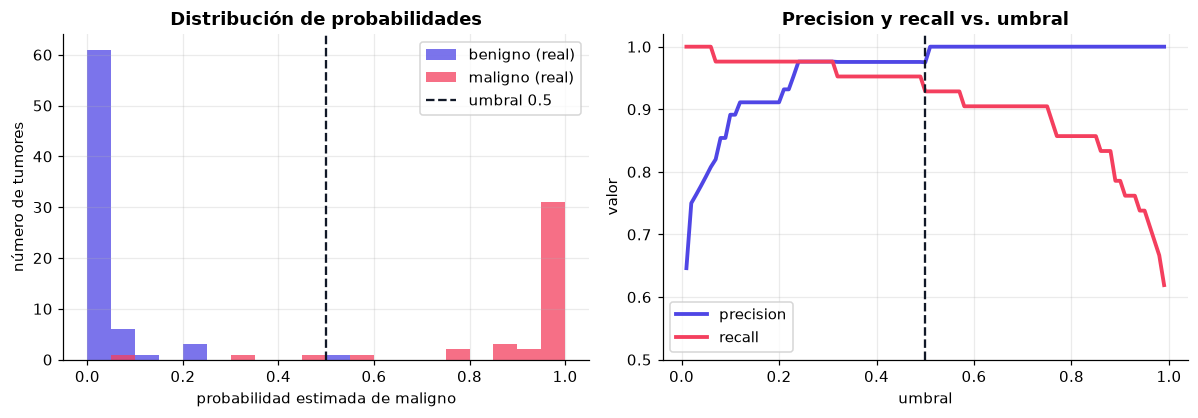

In [28]:
proba = clf.predict_proba(Xc_te)[:, 1]          # probabilidad de "maligno"
umbrales_grid = np.linspace(0.01, 0.99, 99)
prec_u = [precision_score(yc_te, proba >= t, zero_division=1) for t in umbrales_grid]
rec_u  = [recall_score(yc_te, proba >= t) for t in umbrales_grid]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
bins = np.linspace(0, 1, 21)
ax[0].hist(proba[yc_te == 0], bins=bins, color=INDIGO, alpha=0.75, label="benigno (real)")
ax[0].hist(proba[yc_te == 1], bins=bins, color=CORAL, alpha=0.75, label="maligno (real)")
ax[0].axvline(0.5, color=TINTA, ls="--", lw=1.5, label="umbral 0.5")
ax[0].set(xlabel="probabilidad estimada de maligno", ylabel="número de tumores",
          title="Distribución de probabilidades"); ax[0].legend()

ax[1].plot(umbrales_grid, prec_u, color=INDIGO, lw=2.5, label="precision")
ax[1].plot(umbrales_grid, rec_u, color=CORAL, lw=2.5, label="recall")
ax[1].axvline(0.5, color=TINTA, ls="--", lw=1.5)
ax[1].set(xlabel="umbral", ylabel="valor", ylim=(0.5, 1.02), title="Precision y recall vs. umbral"); ax[1].legend()
plt.tight_layout(); plt.show()

*Figura 3.* Izquierda: las probabilidades de ambas clases se separan casi por completo. Derecha: al subir el umbral, la precision aumenta y el recall disminuye.

In [29]:
filas = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    p_t = (proba >= t).astype(int)
    vn, fp, fn, vp = confusion_matrix(yc_te, p_t).ravel()
    filas.append({"umbral": t, "VP": vp, "FP": fp, "FN": fn,
                  "Precision": precision_score(yc_te, p_t), "Recall": recall_score(yc_te, p_t),
                  "F1": f1_score(yc_te, p_t)})
pd.DataFrame(filas).set_index("umbral").round(3)

,VP,FP,FN,Precision,Recall,F1
umbral,,,,,,
0.1,41,5,1,0.891,0.976,0.932
0.3,41,1,1,0.976,0.976,0.976
0.5,39,1,3,0.975,0.929,0.951
0.7,38,0,4,1.000,0.905,0.950
0.9,33,0,9,1.000,0.786,0.880


Bajar el umbral a **0.3** recupera dos de los tres malignos que se escapaban sin añadir falsas alarmas. Subirlo a **0.9** elimina todos los FP pero deja sin detectar 9 de 42 tumores malignos: inaceptable en medicina. **El umbral es una decisión del dominio, no del algoritmo.**

<div style="border-left:5px solid #D97706; background:#FFFBEB; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#D97706; letter-spacing:0.06em;">PRUEBA TÚ · Experimenta con el umbral</span>
<div style="margin-top:6px;">Cambia el valor de <code>umbral</code> en la celda siguiente y observa cómo se mueven los cuatro números de la matriz. ¿Cuál es el umbral más alto que mantiene FN ≤ 1?</div>
</div>

In [30]:
umbral = 0.3   # ← modifica este valor

p_t = (proba >= umbral).astype(int)
print(confusion_matrix(yc_te, p_t))
print(f"precision = {precision_score(yc_te, p_t):.3f}   recall = {recall_score(yc_te, p_t):.3f}")

[[71  1]
 [ 1 41]]
precision = 0.976   recall = 0.976


<div style="border-left:5px solid #F43F5E; background:#FFF1F2; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#F43F5E; letter-spacing:0.06em;">ADVERTENCIA · El umbral también se elige con validación</span>
<div style="margin-top:6px;">En la tabla anterior el umbral 0.3 parece el mejor, pero lo descubrimos <b>mirando el conjunto de prueba</b>: eso vuelve optimista la evaluación (tema 3.3). En un proyecto real el umbral se elige con validación cruzada sobre el entrenamiento —por ejemplo con <code>TunedThresholdClassifierCV</code>— y luego se evalúa <b>una sola vez</b> en prueba.</div>
</div>

In [31]:
from sklearn.model_selection import TunedThresholdClassifierCV

clf_umbral = TunedThresholdClassifierCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    scoring="f1", cv=5, random_state=42,
).fit(Xc_tr, yc_tr)                           # ¡solo datos de entrenamiento!

print(f"Umbral elegido por validación cruzada = {clf_umbral.best_threshold_:.3f}")
print("Evaluación única en prueba:\n", confusion_matrix(yc_te, clf_umbral.predict(Xc_te)))

Umbral elegido por validación cruzada = 0.343
Evaluación única en prueba:
 [[71  1]
 [ 2 40]]


### h) Curva ROC y AUC

Cada umbral produce una matriz de confusión distinta. La **curva ROC** resume todos los umbrales a la vez graficando la tasa de verdaderos positivos frente a la de falsos positivos:

$$TPR = \frac{VP}{VP+FN} \qquad FPR = \frac{FP}{FP+VN} = 1-\text{especificidad} \qquad (3.4.9)$$

- Umbral 1 → nada es positivo → punto $(0,0)$. Umbral 0 → todo es positivo → $(1,1)$.
- Un clasificador perfecto pasa por $(0,1)$; uno aleatorio sigue la diagonal.
- El **AUC** (área bajo la curva) vale 1 para el perfecto y 0.5 para el aleatorio.

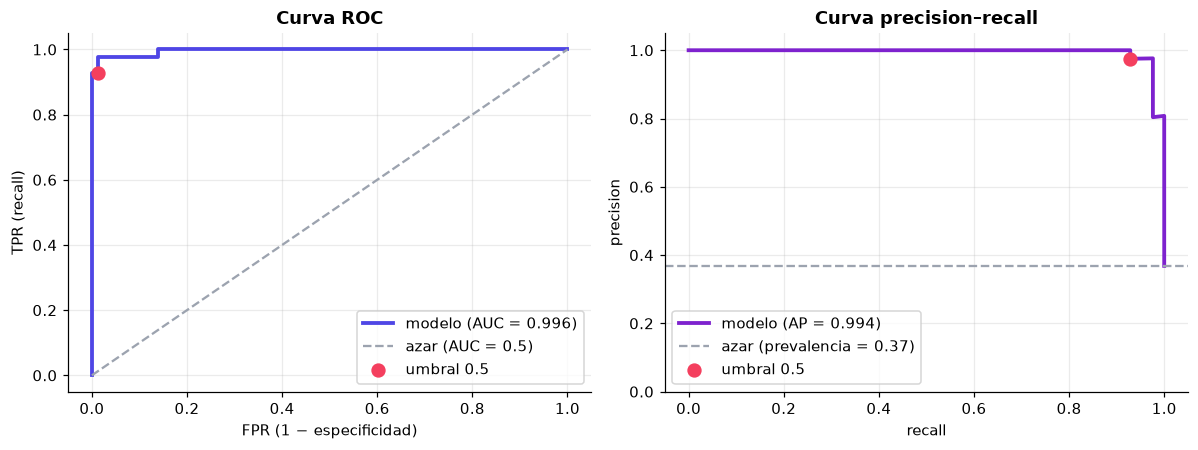

In [32]:
fpr, tpr, umbrales_roc = roc_curve(yc_te, proba)
prec_c, rec_c, _ = precision_recall_curve(yc_te, proba)
auc = roc_auc_score(yc_te, proba)
ap = average_precision_score(yc_te, proba)
prevalencia = yc_te.mean()

# punto correspondiente al umbral 0.5
p05 = (proba >= 0.5).astype(int)
vn, fp, fn, vp = confusion_matrix(yc_te, p05).ravel()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(fpr, tpr, color=INDIGO, lw=2.5, label=f"modelo (AUC = {auc:.3f})")
ax[0].plot([0, 1], [0, 1], "--", color=GRIS, label="azar (AUC = 0.5)")
ax[0].scatter(fp / (fp + vn), vp / (vp + fn), color=CORAL, s=70, zorder=3, label="umbral 0.5")
ax[0].set(xlabel="FPR (1 − especificidad)", ylabel="TPR (recall)", title="Curva ROC"); ax[0].legend(loc="lower right")

ax[1].plot(rec_c, prec_c, color=PURPURA, lw=2.5, label=f"modelo (AP = {ap:.3f})")
ax[1].axhline(prevalencia, ls="--", color=GRIS, label=f"azar (prevalencia = {prevalencia:.2f})")
ax[1].scatter(vp / (vp + fn), vp / (vp + fp), color=CORAL, s=70, zorder=3, label="umbral 0.5")
ax[1].set(xlabel="recall", ylabel="precision", ylim=(0, 1.05), title="Curva precision–recall"); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

*Figura 4.* Curva ROC (izquierda) y curva precision–recall (derecha). El punto coral es el umbral 0.5.

<div style="border-left:5px solid #7E22CE; background:#F5F3FF; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#7E22CE; letter-spacing:0.06em;">DEFINICIÓN · Interpretación probabilística del AUC</span>
<div style="margin-top:6px;">El AUC es la <b>probabilidad de que el modelo asigne una puntuación mayor a un caso positivo elegido al azar que a un caso negativo elegido al azar</b>. Un AUC = 0.996 significa que, al tomar un tumor maligno y uno benigno al azar, en el 99.6 % de los casos el modelo da mayor probabilidad de malignidad al que realmente lo es.</div>
</div>

No hay que creerlo: **comparemos todos los pares** (maligno, benigno) del conjunto de prueba y contemos cuántas veces el maligno recibe mayor puntuación.

In [33]:
p_pos = proba[yc_te.values == 1]          # 42 malignos
p_neg = proba[yc_te.values == 0]          # 72 benignos

comparaciones = p_pos[:, None] > p_neg[None, :]   # matriz 42 × 72 de comparaciones
empates = p_pos[:, None] == p_neg[None, :]
auc_pares = (comparaciones.sum() + 0.5 * empates.sum()) / comparaciones.size

print(f"Pares comparados = {comparaciones.size}")
print(f"AUC por conteo de pares = {auc_pares:.3f}")
print(f"roc_auc_score           = {auc:.3f}")

Pares comparados = 3024
AUC por conteo de pares = 0.996
roc_auc_score           = 0.996


Dos propiedades hacen útil al AUC: **no depende del umbral** (evalúa la capacidad de *ordenar*) y **no depende de la proporción de clases**. Por eso es la métrica preferida para comparar clasificadores antes de fijar un umbral.

### i) Curva precision–recall

Con una clase positiva **muy minoritaria**, la ROC puede ser engañosamente optimista: con muchísimos negativos, incluso cientos de FP dan una FPR pequeña. La curva precision–recall **no usa los VN**, así que refleja mejor el desempeño sobre la clase rara. Se resume con la **precisión promedio (AP)**, y su línea de referencia no es 0.5 sino la **prevalencia**.

In [34]:
print(f"AUC ROC = {auc:.3f}")
print(f"AP      = {ap:.3f}")
print(f"Prevalencia (referencia de AP) = {yc_te.sum()}/{len(yc_te)} = {prevalencia:.2f}")

AUC ROC = 0.996
AP      = 0.994
Prevalencia (referencia de AP) = 42/114 = 0.37


<div style="border-left:5px solid #F43F5E; background:#FFF1F2; color:#111827; padding:12px 16px; border-radius:6px; margin:6px 0;">
<span style="font-family:'IBM Plex Mono',Consolas,monospace; font-size:0.8em; font-weight:700; color:#F43F5E; letter-spacing:0.06em;">ADVERTENCIA · Error frecuente: pasar predict en vez de predict_proba</span>
<div style="margin-top:6px;"><code>roc_auc_score</code> y <code>average_precision_score</code> necesitan las <b>probabilidades</b> para recorrer todos los umbrales. Si reciben la salida de <code>predict</code> (solo 0 y 1) evalúan un único umbral y el resultado ya no es el AUC del modelo.</div>
</div>

In [35]:
print(f"AUC con predict_proba (correcto)   = {roc_auc_score(yc_te, proba):.3f}")
print(f"AUC con predict       (incorrecto) = {roc_auc_score(yc_te, pred_c):.3f}")

AUC con predict_proba (correcto)   = 0.996
AUC con predict       (incorrecto) = 0.957


### j) ¿Qué métrica de clasificación usar?

| Situación | Métrica recomendada |
|---|---|
| Clases balanceadas y errores de costo similar | accuracy |
| Los falsos negativos son costosos | recall (sensibilidad), F2 |
| Los falsos positivos son costosos | precision, F0.5 |
| Se busca equilibrio en la clase positiva | F1 |
| Comparar modelos antes de fijar un umbral | AUC ROC |
| Clase positiva muy rara (fraude, fallas) | curva precision–recall, AP |
| Varias clases desbalanceadas | F1 con promedio macro |
| **Siempre** | la matriz de confusión completa |